# 2.0 ReID subset checks (RoundaboutHD)
The ReID subset is a folder of vehicle crops, named `{id}_cam{cam}_{frame}.jpg`.

**ReID evaluation in short:** each *query* image is compared (embedding distance) against all *gallery* (= `test_images`)
images; the ranked list is scored with Rank-1 / mAP. Standard protocol (Market-1501 / VeRi): train IDs and test IDs are
**disjoint**, and gallery images of the query's ID **from the same camera are ignored** when scoring that query.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from src.data.load import ROOT, load_reid_index, add_image_info, link_reid
pd.set_option("display.width", 160)

## 1. Parse file names

In [2]:
r = add_image_info(load_reid_index())  # + width/height and md5 per file (fails loudly on unreadable images)
print("unparseable names:", r.id.isna().sum())
print(r.groupby("split").agg(images=("path", "size"), ids=("id", "nunique"), id_min=("id", "min"), id_max=("id", "max"),
                             frame_min=("frame", "min"), frame_max=("frame", "max")))
r.groupby(["split", "cam"]).size().unstack()

unparseable names: 0
       images  ids  id_min  id_max  frame_min  frame_max
split                                                   
query    1171  310       3     753          6       8975
test    23225  310       3     753          6       8993
train   41126  511       3     954          6       8993


cam,1,2,3,4
split,,,,
query,347,287,343,194
test,4614,5672,8417,4522
train,9732,8816,13133,9445


## 2. Split integrity

In [3]:
ids = {k: set(v.id) for k, v in r.groupby("split")}
print("train ∩ test IDs :", len(ids["train"] & ids["test"]), "of", len(ids["test"]))
print("train ∩ query IDs:", len(ids["train"] & ids["query"]))
print("query ⊆ test     :", ids["query"] <= ids["test"])

train ∩ test IDs : 310 of 310
train ∩ query IDs: 310
query ⊆ test     : True


In [4]:
# Same ID in train and test: same vehicle (frames interleaved within the same track) or just reused numbers?
tr, te = r[r.split == "train"], r[r.split == "test"]
pairs = set(zip(te.id, te.cam))
shared = pairs & set(zip(tr.id, tr.cam))
print(f"test (id, cam) pairs also in train: {len(shared)}/{len(pairs)}")
i, c = sorted(shared)[0]
print(f"example id {i} cam {c}: train frames {sorted(tr[(tr.id==i)&(tr.cam==c)].frame)[:10]}")
print(f"                     test frames  {sorted(te[(te.id==i)&(te.cam==c)].frame)[:10]}")

test (id, cam) pairs also in train: 832/832
example id 3 cam 1: train frames [314, 317, 320, 323, 329, 390, 393, 396, 402, 406]
                     test frames  [311, 316, 321, 326, 389, 394, 399, 405, 412, 417]


In [5]:
# Exact duplicate files (md5 of the bytes)
dup = r[r.md5.duplicated(keep=False)]
print("files with an identical copy:", len(dup))
print(dup.groupby("md5").split.agg(lambda s: "+".join(sorted(s))).value_counts())

files with an identical copy: 1300
split
query+test     458
query+train    192
Name: count, dtype: int64


In [6]:
# Cross-camera evaluability: does every query have a gallery image of its ID from another camera?
q = r[r.split == "query"]
gal_cams = te.groupby("id").cam.agg(set)
q_ok = [bool(gal_cams.get(i, set()) - {c}) for i, c in zip(q.id, q.cam)]
print(f"queries with a cross-camera gallery match: {sum(q_ok)}/{len(q)}")
print("query IDs seen in only 1 camera (whole subset):", (r[r.id.isin(ids['query'])].groupby('id').cam.nunique() == 1).sum())

queries with a cross-camera gallery match: 1163/1171
query IDs seen in only 1 camera (whole subset): 6


## 3. Statistics per ID

cameras per ID: {1: 207, 2: 159, 3: 72, 4: 73}
{'count': 511.0, 'mean': 128.2, 'std': 85.0, 'min': 1.0, '25%': 54.0, '50%': 115.0, '75%': 192.0, 'max': 507.0}


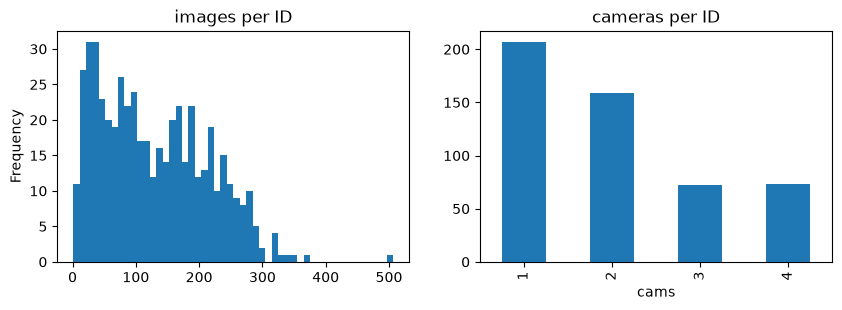

In [7]:
per_id = r.groupby("id").agg(images=("path", "size"), cams=("cam", "nunique"))
print("cameras per ID:", per_id.cams.value_counts().sort_index().to_dict())
print(per_id.images.describe().round(1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
per_id.images.plot.hist(bins=50, ax=ax[0], title="images per ID")
per_id.cams.value_counts().sort_index().plot.bar(ax=ax[1], title="cameras per ID"); plt.show()

## 4. Image quality (size from the header only, no full decode)

             w        h
count  65522.0  65522.0
mean     224.8    145.6
std      182.6    133.7
min       47.0     35.0
25%      114.0     70.0
50%      160.0    101.0
75%      260.0    160.0
max     2183.0   1737.0
crops with min side < 32 px: 0 | < 20 px: 0


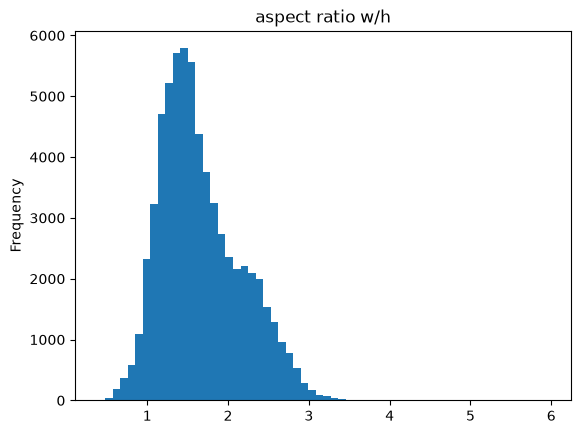

In [8]:
print(r[["w", "h"]].describe().round(1))
print("crops with min side < 32 px:", (r[["w", "h"]].min(axis=1) < 32).sum(), "| < 20 px:", (r[["w", "h"]].min(axis=1) < 20).sum())
(r.w / r.h).plot.hist(bins=60, title="aspect ratio w/h"); plt.show()

## 5. Link crops to the annotations
File-name IDs are **not** the Multi-CAM IDs. Crops are cut from SCT boxes, so we match by (cam, frame) + crop size.
The ReID frame is 0-based (like the detection files): ReID frame f ↔ SCT frame f+1.

In [9]:
# Then SCT (cam, track) -> global Multi-CAM id via identical boxes (see notebook 1). Code: src/data/load.py:link_reid
r = link_reid(r)
print(f"crops linked to an SCT track: {r.track_id.notna().mean():.2%}")
print(f"crops with a global (cross-camera) id: {r.gid.notna().mean():.2%}")

crops linked to an SCT track: 99.93%
crops with a global (cross-camera) id: 85.30%


In [10]:
# Is the file-name id consistent with the annotations? (one id -> one track per cam, one global id)
lr = r.dropna(subset=["track_id"])
print("file ids mapping to >1 SCT track in the same cam:", (lr.groupby(["id", "cam"]).track_id.nunique() > 1).sum())
lg = r.dropna(subset=["gid"])
print("file ids mapping to >1 global id:", (lg.groupby("id").gid.nunique() > 1).sum(), "of", lg.id.nunique())
print("global ids mapping to >1 file id:", (lg.groupby("gid").id.nunique() > 1).sum())
print("file ids without any global id:", r.groupby("id").gid.apply(lambda s: s.isna().all()).sum())

file ids mapping to >1 SCT track in the same cam: 21
file ids mapping to >1 global id: 15 of 315
global ids mapping to >1 file id: 16
file ids without any global id: 196


In [11]:
# How big are these conflicts? Few minority crops -> size-matching noise; many -> real ID label errors.
def conflicts(df, key, val):
    rows = []
    for k, s in df.groupby(key)[val]:
        vc = s.value_counts()
        if len(vc) > 1:
            rows.append({"key": k, "crops": len(s), "minority_crops": vc.iloc[1:].sum(), "counts": dict(vc)})
    return pd.DataFrame(rows)

for name, (df, key, val) in {"(id, cam) -> track": (lr, ["id", "cam"], "track_id"),
                             "id -> global id": (lg, "id", "gid"), "global id -> id": (lg, "gid", "id")}.items():
    cf = conflicts(df, key, val)
    print(f"--- {name}: {len(cf)} conflicts, {cf.minority_crops.sum() if len(cf) else 0} minority crops")
    if len(cf): display(cf.sort_values("minority_crops", ascending=False).head(8))

--- (id, cam) -> track: 21 conflicts, 27 minority crops


,key,crops,minority_crops,counts
19,"(953, 4)",8,4,"{364.0: 4, 365.0: 4}"
3,"(322, 3)",201,2,"{351.0: 199, 342.0: 2}"
6,"(506, 1)",61,2,"{405.0: 59, 404.0: 2}"
14,"(697, 1)",52,2,"{335.0: 50, 337.0: 2}"
0,"(204, 3)",117,1,"{222.0: 116, 228.0: 1}"
12,"(664, 3)",78,1,"{175.0: 77, 174.0: 1}"
18,"(863, 3)",45,1,"{152.0: 44, 150.0: 1}"
17,"(835, 2)",75,1,"{38.0: 74, 35.0: 1}"


--- id -> global id: 15 conflicts, 296 minority crops


,key,crops,minority_crops,counts
11,673,507,192,"{469.0: 315, 664.0: 192}"
7,592,147,52,"{161.0: 95, 78.0: 52}"
8,653,172,38,"{644.0: 134, 87.0: 38}"
3,506,122,2,"{500.0: 120, 728.0: 2}"
13,697,218,2,"{688.0: 216, 56.0: 2}"
0,204,188,1,"{201.0: 187, 660.0: 1}"
1,281,139,1,"{277.0: 138, 657.0: 1}"
2,347,230,1,"{343.0: 229, 341.0: 1}"


--- global id -> id: 16 conflicts, 422 minority crops


,key,crops,minority_crops,counts
13,664.0,364,172,"{673: 192, 25: 110, 852: 62}"
8,644.0,355,134,"{606: 221, 653: 134}"
7,553.0,305,100,"{560: 205, 872: 99, 563: 1}"
1,56.0,90,2,"{57: 88, 697: 2}"
9,650.0,239,2,"{659: 237, 863: 1, 658: 1}"
15,728.0,286,2,"{737: 284, 506: 2}"
0,9.0,156,1,"{10: 155, 766: 1}"
2,76.0,76,1,"{77: 75, 591: 1}"


## 6. Visual check

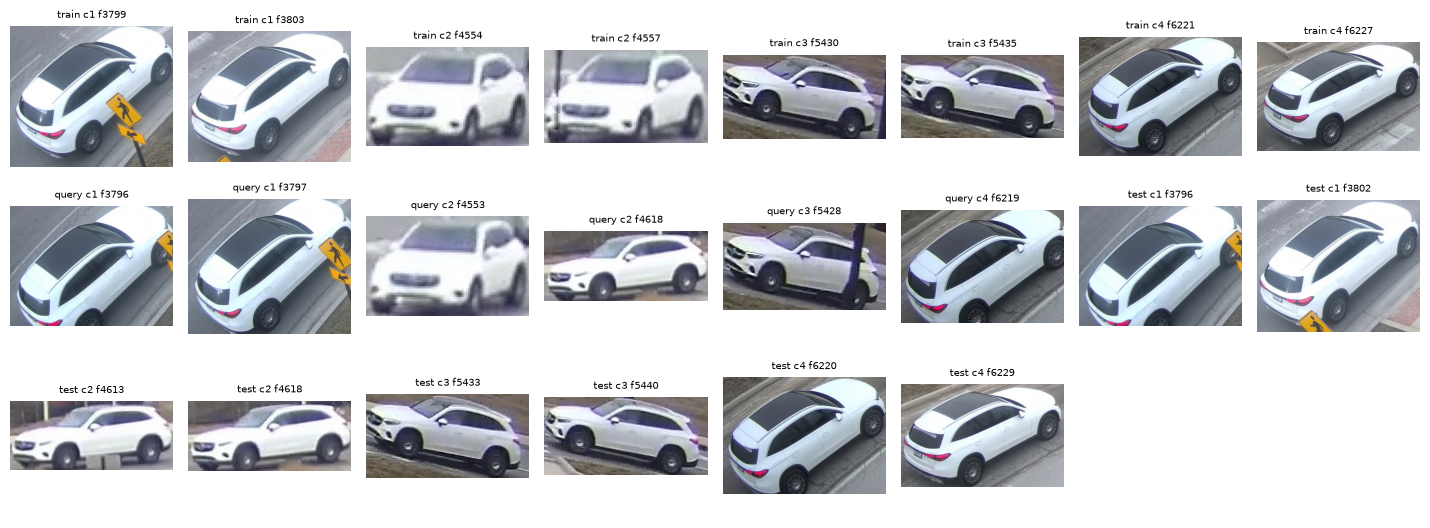

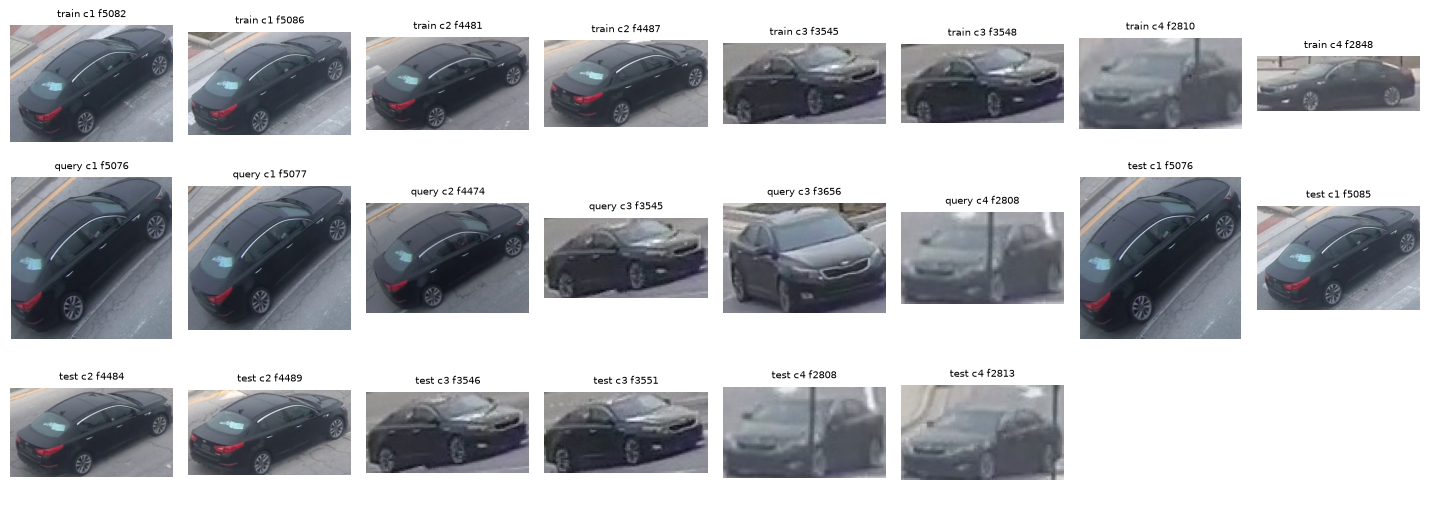

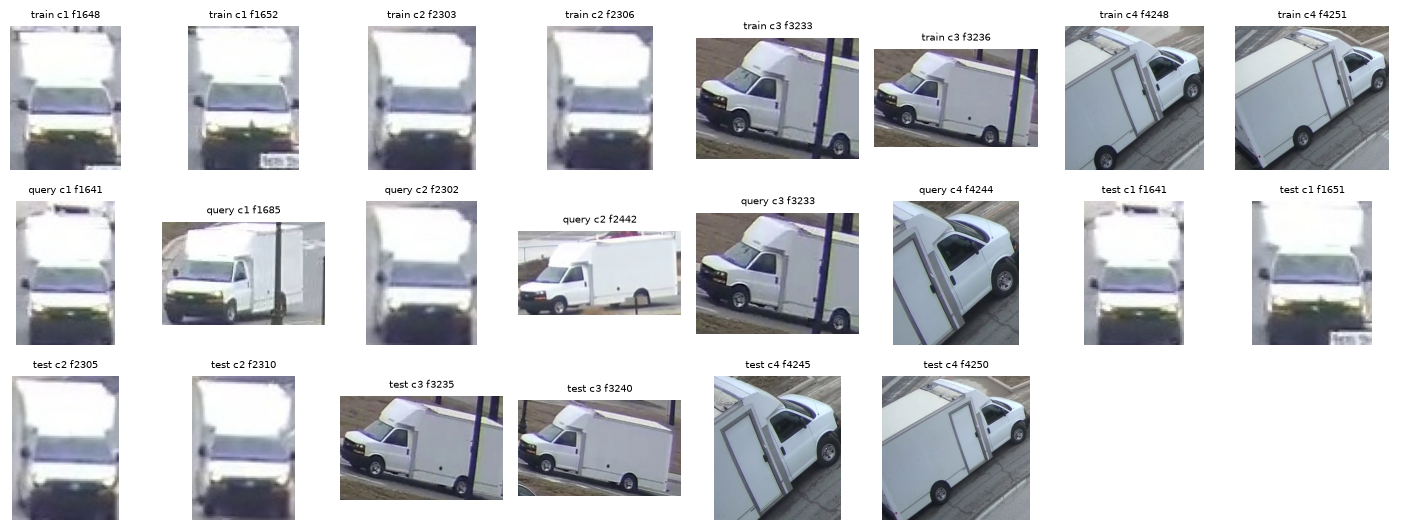

In [12]:
def grid(paths, titles, ncol=8, size=1.8):
    n = len(paths); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size))
    for ax in np.ravel(axs): ax.axis("off")
    for ax, p, t in zip(np.ravel(axs), paths, titles):
        ax.imshow(Image.open(ROOT / p)); ax.set_title(t, fontsize=7)
    plt.tight_layout(); plt.show()

# one ID across splits and cameras: same vehicle in train and test?
for vid in per_id[per_id.cams == 4].sample(3, random_state=1).index:
    s = r[r.id == vid].groupby(["split", "cam"]).head(2)
    grid(s.path.tolist(), [f"{a} c{b} f{c}" for a, b, c in zip(s.split, s.cam, s.frame)])

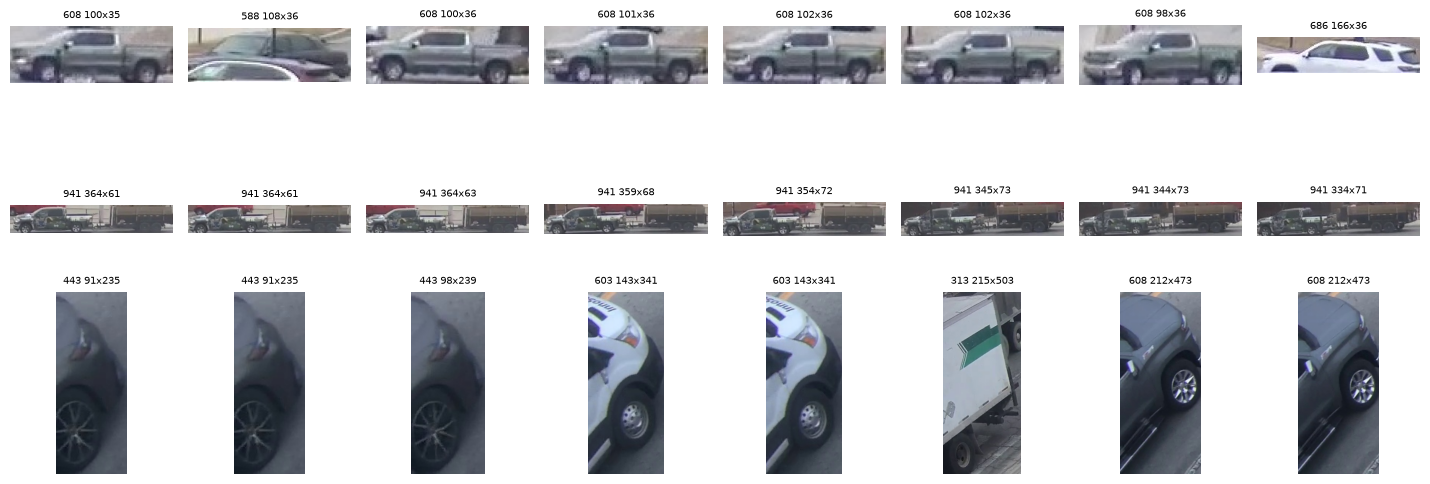

In [13]:
# smallest crops and most extreme aspect ratios
s = pd.concat([r.nsmallest(8, "h"), r.assign(ar=r.w / r.h).nlargest(8, "ar"), r.assign(ar=r.w / r.h).nsmallest(8, "ar")])
grid(s.path.tolist(), [f"{a} {int(w)}x{int(h)}" for a, w, h in zip(s.id, s.w, s.h)])

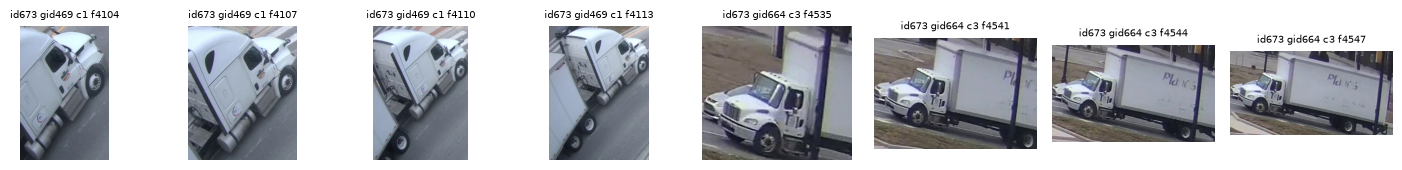

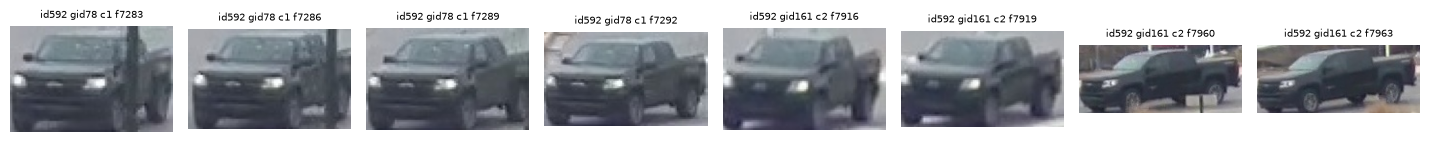

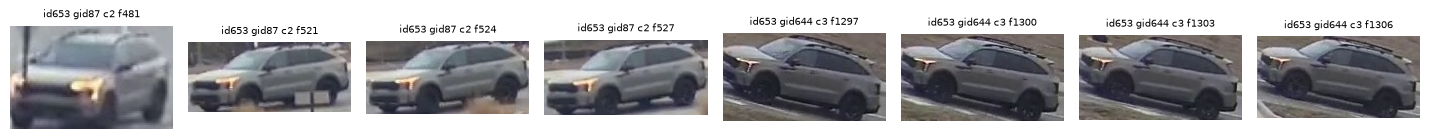

In [14]:
# Real ID conflicts (file id split across global ids): same vehicle or two different ones?
for vid in [673, 592, 653]:
    s = r[r.id == vid].dropna(subset=["gid"]).groupby("gid").head(4)
    grid(s.path.tolist(), [f"id{vid} gid{int(g)} c{c} f{f}" for g, c, f in zip(s.gid, s.cam, s.frame)])

## 7. Findings

**Split is by image, not by vehicle ID → train/test leakage**
- All 310 query/test IDs also appear in train (832/832 (id, cam) pairs), with **interleaved frames of the same track**
  (e.g. id 3 cam 1: train 314, 317, 320 … / test 311, 316, 321 …). The visual grid confirms it's the same vehicle.
  Models trained on `train_images` have seen the test vehicles → scores on the official split are inflated.
- **458 query images are byte-identical copies of gallery images**, 192 are identical to train images.
  Under the standard protocol (same-camera gallery ignored) the query–gallery copies are excluded anyway, but a naive
  evaluation would match each query to itself.
- 8 queries (6 IDs) have no gallery image from another camera → can't be scored cross-camera.

**IDs**
- File-name IDs are their own numbering: **not** the Multi-CAM global IDs and not the SCT track ids.
- Link via (cam, frame+1, crop size) → SCT track works for 99.9% of crops, → global id for 85% (the rest are vehicles only
  in single-camera GT; 207 of 511 file IDs are seen in one camera only).
- A few **real ID conflicts** between ReID labels and Multi-CAM GT (the rest are 1–2 crops of matching noise), errors on both sides:
  - **ReID label error:** file id 673 merges two different vehicles (semi-truck tractor in cam 1, box truck in cam 3).
  - **Multi-CAM error:** file ids 592 (dark pickup, gid 78 + 161) and 653 (grey SUV, gid 87 + 644) are the same vehicle,
    but the Multi-CAM GT gives them two global ids. gid 78/87 are among the "single-camera" ids → missed cross-camera links.
  - Not yet inspected: global ids 553 (file ids 560/872) and 664/644 (file ids 25/852/606).

**Images**
- 65,522 crops, all readable, no tiny crops (min 47×35 px). Size varies a lot (median 160×101, max 2183×1737)
  → resize to a fixed input (e.g. 256×256) at training time.
- Images per ID: median 115, min 1 – unbalanced → PK sampler handles this; drop IDs with < 2 images.